<a href="https://colab.research.google.com/github/farrelrassya/LLM-Design-Patterns-Building-Robust-and-Efficient-AI-Systems/blob/main/01.Introduction_to_LLM_Design_Patterns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 1 — Pengenalan LLM Design Patterns

*Notebook pendamping untuk buku* LLM Design Patterns

> **Cara membuka di Colab.** Revisi ini belum dipublikasikan ke repositori, jadi belum ada tautan "Open in Colab" yang benar. Unggah file ini sendiri: buka [colab.research.google.com](https://colab.research.google.com), pilih **File → Upload notebook**, lalu pilih `01.Introduction_to_LLM_Design_Patterns.COLAB_GPU_READY.ipynb`. Sebelum **Runtime → Run all**, atur **Runtime → Change runtime type → T4 GPU** (GPU lain juga boleh).

Bab pembuka buku ini tidak berisi listing kode. Isinya serangkaian klaim: model statistik kalah oleh transformer karena transformer memakai konteks, self-attention menimbang hubungan antar-token, performa membaik seiring ukuran model, LLM bisa mengerjakan tugas baru dari beberapa contoh di prompt, kemampuannya timpang antarbahasa, dan pengembangan LLM bisa dipetakan ke 29 pola desain.

Notebook ini memperlakukan klaim-klaim itu sebagai pertanyaan yang bisa dicek. Karena bukunya tidak punya kode, semua kode di sini adalah eksperimen pendamping, bukan perbaikan listing buku. Setiap eksperimen menguji satu klaim dengan model kecil yang nyata (GPT-2 124M, Pythia 14M–410M, BLOOM-560M) dan data publik. Hasilnya menggambarkan model-model ini, bukan hukum untuk semua LLM.

| Bagian | Klaim yang diuji | Perangkat |
|---|---|---|
| 1. Dari hitungan ke konteks | transformer unggul karena memakai konteks | bigram: CPU · GPT-2: GPU |
| 2. Token dan vektor | teks → token → vektor padat | CPU |
| 3. Attention | setiap token menimbang token lain; head berspesialisasi | GPU |
| 4. Skala | performa membaik seiring ukuran; skala menuntut sumber daya | estimasi: CPU · pengukuran: GPU |
| 5. Few-shot | beberapa contoh di prompt cukup untuk tugas baru | GPU |
| 6. Generasi | teks yang dihasilkan lancar | GPU |
| 7. Multibahasa | kemampuan timpang antarbahasa | tokenizer: CPU · model: GPU |
| 8. Design pattern | 29 pola dalam enam kelompok | CPU |

> **Status pengujian.** Notebook ini belum pernah dijalankan penyusun di CUDA atau Colab. Yang sudah dijalankan hanya profil kecil `cpu_smoke` di CPU lokal (rinciannya di `CHANGES_AND_VALIDATION.md`). Angka berlabel **run historis** di narasi berasal dari notebook asli (CPU, fp32, profil penuh); angka berlabel **run lokal** berasal dari CPU penyusun. Output Anda di Colab adalah hasil aktual, jadi baca itu lebih dulu. Angka dari profil `cpu_smoke` tidak sebanding dengan profil GPU karena datanya lebih sedikit.

## Mulai dari satu pertanyaan: kata apa berikutnya?

Semua model di bab ini, dari tabel hitungan sampai GPT, mengerjakan tugas yang sama: diberi potongan teks, tebak *token* berikutnya. Token adalah satuan teks yang dibaca model; untuk sekarang anggap saja kata.

Ambil dua kalimat yang ujungnya sama persis:

- *The dog ran around the park all afternoon, so by evening it was too ___*
- *The truck could not fit through the narrow gate because it was too ___*

Pembaca manusia mengisi *tired* untuk yang pertama dan *wide* (atau *big*) untuk yang kedua. Petunjuknya ada di *dog* dan *truck*, jauh di depan. Model statistik paling sederhana, **bigram**, hanya melihat satu kata terakhir, dan di kedua kalimat kata itu sama: *too*. Sel berikut membangun bigram dari tujuh kalimat mainan untuk melihat akibatnya. Kodenya Python murni di CPU; belum ada model neural.

In [1]:
from collections import Counter, defaultdict

toy_corpus = [
    "the dog was too tired",
    "the puppy was too tired",
    "the old dog was too tired",
    "the truck was too wide",
    "the bus was too wide",
    "the dog was too hungry",
    "the truck was too heavy",
]

toy_bigram = defaultdict(Counter)
for sentence in toy_corpus:
    words = sentence.split()
    for prev, nxt in zip(words, words[1:]):
        toy_bigram[prev][nxt] += 1


def toy_next_word(prompt):
    last = prompt.lower().split()[-1]
    counts = toy_bigram[last]
    total = sum(counts.values())
    return last, {word: round(c / total, 2) for word, c in counts.most_common()}


for prompt in ["The dog ran around the park all afternoon, so by evening it was too",
               "The truck could not fit through the narrow gate because it was too"]:
    last, dist = toy_next_word(prompt)
    print(f"{prompt}\n  bigram hanya melihat {last!r} -> {dist}")

The dog ran around the park all afternoon, so by evening it was too
  bigram hanya melihat 'too' -> {'tired': 0.43, 'wide': 0.29, 'hungry': 0.14, 'heavy': 0.14}
The truck could not fit through the narrow gate because it was too
  bigram hanya melihat 'too' -> {'tired': 0.43, 'wide': 0.29, 'hungry': 0.14, 'heavy': 0.14}


Kedua kalimat mendapat tebakan yang persis sama: *tired* 3/7 ≈ 0,43, *wide* 2/7 ≈ 0,29. Bigram tidak salah hitung; bahannya memang hanya satu kata, dan kata itu sama. Melihat dua kata (*was too*) juga belum menolong, karena petunjuk *dog* dan *truck* ada jauh di depan.

Jalan keluar bagi model hitungan adalah memperpanjang jendelanya, dan di situ ia buntu. Dengan kosakata 50 ribu token, jendela empat token sudah punya 50.000⁴ ≈ 6 × 10¹⁸ kemungkinan konteks, jauh melampaui teks apa pun yang bisa dihitung. Transformer menempuh jalan lain: alih-alih menyimpan tabel per konteks, ia belajar *membaca* konteks. Sisa notebook mengikuti dua kalimat ini dari tabel hitungan ke transformer, lalu ke few-shot, generasi, bahasa lain, dan design pattern.

## Persiapan: paket, gerbang GPU, dan profil

Tiga sel berikut menyiapkan lingkungan. Sel pertama hanya memasang paket yang kurang; Colab biasanya sudah punya semuanya. Sel kedua memuat pustaka dan mendefinisikan dua profil. Sel ketiga adalah **gerbang CUDA**: ia tidak sekadar bertanya apakah GPU ada, tetapi mengalokasikan matriks di GPU, mengalikannya, menunggu GPU selesai (`torch.cuda.synchronize`), dan memeriksa bahwa hasilnya tidak berisi NaN atau inf. Kalau CUDA tidak ada, notebook berhenti dengan petunjuk dan tidak diam-diam pindah ke CPU.

Tidak semua pekerjaan di bab ini perlu GPU. Menghitung bigram, menjalankan tokenizer, dan menghitung parameter adalah pekerjaan CPU, dan diberi label begitu. GPU dipakai untuk semua forward pass model neural: skor loss, attention, few-shot, dan generasi. Profil CPU (`cpu_smoke`) hanya aktif kalau Anda sengaja mengubah `ALLOW_CPU_SMOKE = True`; profil itu memakai lebih sedikit data dan model yang lebih kecil.

In [2]:
# Pasang hanya yang belum ada atau terlalu lama. `dtype=` di from_pretrained butuh transformers >= 4.56.
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

REQUIREMENTS = {"transformers": (4, 56), "datasets": (2, 19)}


def installed_version(package):
    try:
        return version(package)
    except PackageNotFoundError:
        return None


def major_minor(text):
    major, minor = text.split(".")[:2]
    return int(major), int("".join(ch for ch in minor if ch.isdigit()) or 0)


to_install = [f"{pkg}>={a}.{b}" for pkg, (a, b) in REQUIREMENTS.items()
              if installed_version(pkg) is None or major_minor(installed_version(pkg)) < (a, b)]
if to_install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *to_install])
    print("dipasang:", to_install, "-> jika sel impor sudah pernah dijalankan, lakukan Runtime -> Restart session sekali")
for package in ["torch", "transformers", "datasets", "safetensors", "huggingface_hub"]:
    print(f"{package:<16} {installed_version(package)}")

torch            2.11.0+cu130
transformers     5.20.2
datasets         4.8.5
safetensors      0.8.0
huggingface_hub  1.33.0


In [3]:
import gc
import math
import os
import random
import re
import time

import datasets
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from datasets import load_dataset
from huggingface_hub import hf_hub_download
from safetensors import safe_open
from transformers import AutoModelForCausalLM, AutoTokenizer

transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
datasets.logging.set_verbosity_error()
datasets.disable_progress_bars()

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Profil CPU hanya untuk uji kecil yang disengaja. Biarkan False di Colab GPU.
ALLOW_CPU_SMOKE = False
ALLOW_CPU_SMOKE = ALLOW_CPU_SMOKE or os.environ.get("LDP01_ALLOW_CPU_SMOKE") == "1"

GPT2_ID = "openai-community/gpt2"
PYTHIA_TOKENIZER_ID = "EleutherAI/pythia-160m"
BLOOM_ID = "bigscience/bloom-560m"
QWEN_TOKENIZER_ID = "Qwen/Qwen2.5-0.5B"

PROFILES = {
    "colab_gpu": {
        "wiki_windows": 8,
        "census_tokens": 512,
        "dtype_probe_model": "EleutherAI/pythia-160m",
        "scaling_models": ["pythia-14m", "pythia-31m", "pythia-70m", "pythia-160m", "pythia-410m"],
        "scaling_windows": 16,
        "fewshot_models": ["pythia-70m", "pythia-160m", "pythia-410m"],
        "fewshot_per_label": 80,
        "gen_tokens": 80,
        "bits_models": [GPT2_ID, BLOOM_ID],
    },
    "cpu_smoke": {
        "wiki_windows": 2,
        "census_tokens": 256,
        "dtype_probe_model": "EleutherAI/pythia-70m",
        "scaling_models": ["pythia-14m", "pythia-31m", "pythia-70m"],
        "scaling_windows": 4,
        "fewshot_models": ["pythia-70m"],
        "fewshot_per_label": 20,
        "gen_tokens": 40,
        "bits_models": [GPT2_ID],
    },
}

print("python      :", sys.version.split()[0])
print("torch       :", torch.__version__, "| build CUDA:", torch.version.cuda)
print("transformers:", transformers.__version__, "| datasets:", datasets.__version__)

python      : 3.13.16
torch       : 2.11.0+cu130 | build CUDA: 13.0
transformers: 5.20.2 | datasets: 4.8.5


In [4]:
def functional_cuda_check(size=2048):
    # Alokasi + matmul + synchronize + cek finite. Error CUDA atau OOM sengaja dibiarkan menghentikan notebook.
    device = torch.device("cuda")
    a = torch.randn(size, size, device=device)
    b = a @ a.T
    torch.cuda.synchronize()
    if not bool(torch.isfinite(b).all()):
        raise RuntimeError("Gerbang CUDA gagal: hasil matmul berisi NaN/inf.")
    free_bytes, total_bytes = torch.cuda.mem_get_info()
    del a, b
    torch.cuda.empty_cache()
    return {
        "name": torch.cuda.get_device_name(0),
        "capability": torch.cuda.get_device_capability(0),
        "free_gb": free_bytes / 1e9,
        "total_gb": total_bytes / 1e9,
    }


if torch.cuda.is_available():
    GPU_INFO = functional_cuda_check()
    DEVICE = torch.device("cuda")
    PROFILE_NAME = "colab_gpu"
    # T4 (compute capability 7.5) tidak punya bf16 native; GPU Ampere ke atas (>= 8.0) punya.
    HALF_DTYPE = torch.bfloat16 if GPU_INFO["capability"][0] >= 8 else torch.float16
    MEMORY_GB = GPU_INFO["total_gb"]
    MEMORY_LABEL = "VRAM GPU"
    print(f"GPU OK: {GPU_INFO['name']} | compute capability {GPU_INFO['capability']} | "
          f"memori bebas {GPU_INFO['free_gb']:.1f} / {GPU_INFO['total_gb']:.1f} GB | half precision: {HALF_DTYPE}")
elif ALLOW_CPU_SMOKE:
    GPU_INFO = None
    DEVICE = torch.device("cpu")
    PROFILE_NAME = "cpu_smoke"
    HALF_DTYPE = torch.float16
    MEMORY_GB = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9
    MEMORY_LABEL = "RAM CPU"
    print("PERINGATAN: CUDA tidak ada dan ALLOW_CPU_SMOKE aktif. Profil cpu_smoke memakai data dan model "
          "yang diperkecil; angkanya tidak sebanding dengan profil GPU.")
else:
    raise RuntimeError(
        "CUDA tidak tersedia. Notebook dihentikan supaya tidak diam-diam berjalan di CPU.\n"
        "Di Colab: Runtime -> Change runtime type -> Hardware accelerator: GPU (mis. T4) -> Save, "
        "lalu Runtime -> Run all.\n"
        "Untuk sengaja memakai profil CPU kecil, set ALLOW_CPU_SMOKE = True di sel sebelumnya.")

PROFILE = PROFILES[PROFILE_NAME]
MODEL_DTYPE = torch.float32  # semua pengukuran loss memakai fp32; half precision diuji terpisah di bagian 4
print(f"device: {DEVICE} | profil: {PROFILE_NAME} | dtype model untuk pengukuran: {MODEL_DTYPE}")

GPU OK: Tesla T4 | compute capability (7, 5) | memori bebas 15.4 / 15.6 GB | half precision: torch.float16
device: cuda | profil: colab_gpu | dtype model untuk pengukuran: torch.float32


Helper berikut dipakai di semua bagian neural. `load_lm` memuat model dengan `dtype` eksplisit dan memindahkannya ke `DEVICE` tanpa `device_map`, jadi tidak ada bagian model yang diam-diam tertinggal di CPU. `assert_on_device` menghentikan notebook bila bobot, buffer, atau input tidak berada di perangkat yang sama. Dua fungsi skor mengembalikan hasilnya ke CPU sebagai float32, supaya NumPy dan Matplotlib bisa memakainya.

In [5]:
def assert_on_device(model, *tensors):
    found = {p.device.type for p in model.parameters()}
    found |= {b.device.type for b in model.buffers()}
    found |= {t.device.type for t in tensors}
    if found != {DEVICE.type}:
        raise RuntimeError(f"Penempatan tidak konsisten: diharapkan {DEVICE.type}, ditemukan {found}")


def load_lm(name, dtype=MODEL_DTYPE, **kwargs):
    model = AutoModelForCausalLM.from_pretrained(name, dtype=dtype, **kwargs).to(DEVICE).eval()
    assert_on_device(model)
    return model


def free_memory():
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def require_finite(tensor, what):
    if not bool(torch.isfinite(tensor).all()):
        raise FloatingPointError(f"{what}: hasil berisi NaN/inf")
    return tensor


def right_padded_batch(seqs, pad_id):
    width = max(len(s) for s in seqs)
    ids = torch.full((len(seqs), width), pad_id, dtype=torch.long)
    mask = torch.zeros((len(seqs), width), dtype=torch.long)
    for row, s in enumerate(seqs):
        ids[row, :len(s)] = torch.tensor(s)
        mask[row, :len(s)] = 1
    return ids.to(DEVICE), mask.to(DEVICE)


@torch.no_grad()
def token_nll(model, seqs, pad_id, batch_size=8):
    # NLL (nats) setiap token target; satu tensor CPU float32 per urutan.
    out = []
    for start in range(0, len(seqs), batch_size):
        chunk = seqs[start:start + batch_size]
        ids, mask = right_padded_batch(chunk, pad_id)
        assert_on_device(model, ids, mask)
        logits = model(input_ids=ids, attention_mask=mask).logits[:, :-1].float()
        nll = -logits.log_softmax(-1).gather(-1, ids[:, 1:, None]).squeeze(-1)
        require_finite(nll, "token_nll")
        out.extend(nll[row, :len(s) - 1].cpu() for row, s in enumerate(chunk))
    return out


@torch.no_grad()
def last_token_logits(model, seqs, pad_id, token_ids=None, batch_size=32):
    # Logit di posisi terakhir setiap urutan. Hanya hidden state terakhir yang melewati lapisan output.
    head = model.get_output_embeddings()
    out = []
    for start in range(0, len(seqs), batch_size):
        chunk = seqs[start:start + batch_size]
        ids, mask = right_padded_batch(chunk, pad_id)
        assert_on_device(model, ids, mask)
        hidden = model.base_model(input_ids=ids, attention_mask=mask).last_hidden_state
        last = mask.sum(1) - 1
        logits = head(hidden[torch.arange(len(chunk), device=DEVICE), last]).float()
        if token_ids is not None:
            logits = logits[:, token_ids]
        out.append(require_finite(logits, "last_token_logits").cpu())
    return torch.cat(out)

Data utama bab ini adalah **wikitext-2**, kumpulan artikel Wikipedia. Sel berikut mengunduhnya dan menokenisasinya dengan tokenizer GPT-2. Ini pekerjaan I/O dan CPU.

In [6]:
gpt2_tok = AutoTokenizer.from_pretrained(GPT2_ID)
V = len(gpt2_tok)
wiki = {split: "".join(load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split=split)["text"])
        for split in ("train", "validation", "test")}
wiki_ids = {split: np.array(gpt2_tok(text)["input_ids"], dtype=np.int64) for split, text in wiki.items()}
print(f"kosakata GPT-2: {V:,} token")
print("token wikitext-2:", {split: f"{len(ids):,}" for split, ids in wiki_ids.items()})

kosakata GPT-2: 50,257 token
token wikitext-2: {'train': '2,391,884', 'validation': '247,289', 'test': '283,287'}


## 1. Dari hitungan ke konteks

Tujuh kalimat mainan terlalu kecil untuk membuktikan apa pun. Versi seriusnya: latih bigram dari wikitext-2 train, lalu adu dengan **GPT-2 124M**, transformer kecil yang dirilis OpenAI pada 2019.

Ukurannya adalah **loss**: rata-rata −ln p(token yang benar), dalam satuan *nats per token*. Kalau model memberi peluang 0,5 pada token yang benar, loss-nya ln 2 ≈ 0,69; kalau hanya 0,01, loss-nya 4,6. Makin kecil makin baik. Loss sering ditulis ulang sebagai **perplexity** = e^loss, kira-kira jumlah pilihan yang sama kuat yang sedang ditimbang model setiap kali menebak.

Bigram mentah memberi peluang nol untuk pasangan yang tidak pernah muncul di data latih, jadi peluangnya dicampur dengan **unigram** (frekuensi token tanpa konteks): p = λ · p_bigram + (1 − λ) · p_unigram. Bobot λ dipilih di data validasi, bukan di data uji. Sel ini berjalan di CPU dengan NumPy.

In [7]:
train_ids = wiki_ids["train"]
unigram_counts = np.bincount(train_ids, minlength=V).astype(np.float64)
p_unigram = (unigram_counts + 1) / (unigram_counts.sum() + V)
pair_keys, pair_counts = np.unique(train_ids[:-1] * V + train_ids[1:], return_counts=True)
context_counts = np.bincount(train_ids[:-1], minlength=V).astype(np.float64)


def bigram_logp(prev_ids, next_ids, lam):
    # ln p(next | prev) dari bigram yang dicampur unigram; input berupa array token id yang berpasangan.
    prev_ids = np.asarray(prev_ids)
    next_ids = np.asarray(next_ids)
    keys = prev_ids * V + next_ids
    pos = np.minimum(np.searchsorted(pair_keys, keys), len(pair_keys) - 1)
    c_pair = np.where(pair_keys[pos] == keys, pair_counts[pos], 0).astype(np.float64)
    c_prev = context_counts[prev_ids]
    p_ml = np.divide(c_pair, c_prev, out=np.zeros_like(c_pair), where=c_prev > 0)
    p = np.where(c_prev > 0, lam * p_ml + (1 - lam) * p_unigram[next_ids], p_unigram[next_ids])
    return np.log(p)


val = wiki_ids["validation"][:40000]
LAMBDA = min([0.5, 0.6, 0.7, 0.8, 0.9], key=lambda lam: -bigram_logp(val[:-1], val[1:], lam).mean())

W = 1024
test_windows = wiki_ids["test"][:W * PROFILE["wiki_windows"]].reshape(PROFILE["wiki_windows"], W)
nll_unigram = float(np.mean(-np.log(p_unigram[test_windows[:, 1:]])))
nll_bigram = float(np.mean(-bigram_logp(test_windows[:, :-1], test_windows[:, 1:], LAMBDA)))
print(f"lambda terbaik di validasi: {LAMBDA}")
print(f"data uji: {PROFILE['wiki_windows']} jendela x {W} token")
print(f"unigram: {nll_unigram:.3f} nats/token (perplexity {math.exp(nll_unigram):,.0f})")
print(f"bigram : {nll_bigram:.3f} nats/token (perplexity {math.exp(nll_bigram):,.0f})")

lambda terbaik di validasi: 0.7
data uji: 8 jendela x 1024 token
unigram: 7.416 nats/token (perplexity 1,662)
bigram : 6.104 nats/token (perplexity 448)


Sekarang kembali ke dua kalimat tadi, kali ini dengan bigram wikitext (CPU) dan GPT-2 (GPU). Untuk setiap kalimat dihitung **Δ = ln p(*tired*) − ln p(*wide*)**. Δ positif berarti model lebih condong ke *tired*; Δ = 2 berarti *tired* sekitar e² ≈ 7 kali lebih mungkin daripada *wide*.

In [8]:
gpt2 = load_lm(GPT2_ID)

RUNNING = {
    "anjing": "The dog ran around the park all afternoon, so by evening it was too",
    "truk": "The truck could not fit through the narrow gate because it was too",
}
CANDIDATES = [" tired", " wide"]
assert all(len(gpt2_tok(w)["input_ids"]) == 1 for w in CANDIDATES)
cand_ids = [gpt2_tok(w)["input_ids"][0] for w in CANDIDATES]

prompt_ids = [gpt2_tok(p)["input_ids"] for p in RUNNING.values()]
gpt2_logp = last_token_logits(gpt2, prompt_ids, gpt2_tok.eos_token_id).log_softmax(-1)

for row, (name, ids) in enumerate(zip(RUNNING, prompt_ids)):
    bi = bigram_logp([ids[-1]] * len(cand_ids), cand_ids, LAMBDA)
    gp = gpt2_logp[row, cand_ids].numpy()
    top = gpt2_logp[row].topk(5)
    top_words = ", ".join(f"{gpt2_tok.decode(int(i))!r} {float(v.exp()):.2f}" for v, i in zip(top.values, top.indices))
    print(f"[{name}] token terakhir {gpt2_tok.decode(ids[-1])!r}")
    print(f"   bigram: Δ = {bi[0] - bi[1]:+.2f}")
    print(f"   GPT-2 : Δ = {gp[0] - gp[1]:+.2f} | 5 tebakan teratas: {top_words}")

[anjing] token terakhir ' too'
   bigram: Δ = -0.70
   GPT-2 : Δ = +7.39 | 5 tebakan teratas: ' late' 0.82, ' dark' 0.02, ' cold' 0.02, ' tired' 0.02, ' busy' 0.02
[truk] token terakhir ' too'
   bigram: Δ = -0.70
   GPT-2 : Δ = -6.19 | 5 tebakan teratas: ' big' 0.14, ' small' 0.13, ' narrow' 0.13, ' large' 0.13, ' heavy' 0.09


Bigram memberi Δ yang identik untuk kedua kalimat, karena token terakhirnya sama-sama ` too`; kali ini angkanya berasal dari bigram wikitext, bukan tabel mainan. Di run lokal penyusun (CPU, fp32) Δ bigram adalah −0,70 untuk keduanya: di wikitext, *too wide* sedikit lebih sering daripada *too tired*, apa pun subjek kalimatnya.

GPT-2 memberi tanda yang berlawanan. Di run lokal yang sama, dengan bobot GPT-2 yang sama, Δ-nya +7,39 untuk kalimat anjing dan −6,19 untuk kalimat truk: *tired* sekitar e^7,4 ≈ 1.600 kali lebih mungkin daripada *wide* di kalimat pertama, dan kebalikannya sekitar e^6,2 ≈ 490 kali di kalimat kedua. Di GPU angka ini seharusnya hanya berbeda di digit-digit akhir.

Daftar tebakan teratas memberi pelajaran tambahan. Untuk kalimat anjing, tebakan GPT-2 yang paling yakin justru *late* (run lokal: 0,82), bukan *tired* (0,02), karena *by evening it was too late* adalah frasa yang sangat umum. GPT-2 memang membaca konteks, tetapi konteks yang ia baca mencakup *by evening*, bukan hanya *dog*.

Dua kalimat bukan bukti. Pertanyaan yang lebih adil: apakah GPT-2 secara umum memanfaatkan konteks yang lebih panjang? Sel berikut mengukurnya di teks uji wikitext (GPU), dengan loss dipecah menurut jumlah token konteks yang tersedia di setiap posisi: token ke-2 sebuah jendela hanya punya 1 token konteks, token ke-1.000 punya 999.

GPT-2, konteks penuh: 3.486 nats/token (perplexity 32.7) | bigram 6.104 | unigram 7.416
  konteks    1-1    token: 8.789 nats (selisih vs bigram +2.685)
  konteks    2-4    token: 6.121 nats (selisih vs bigram +0.017)
  konteks    5-16   token: 5.574 nats (selisih vs bigram -0.530)
  konteks   17-64   token: 4.402 nats (selisih vs bigram -1.703)
  konteks   65-256  token: 3.567 nats (selisih vs bigram -2.537)
  konteks  257-1023 token: 3.358 nats (selisih vs bigram -2.746)


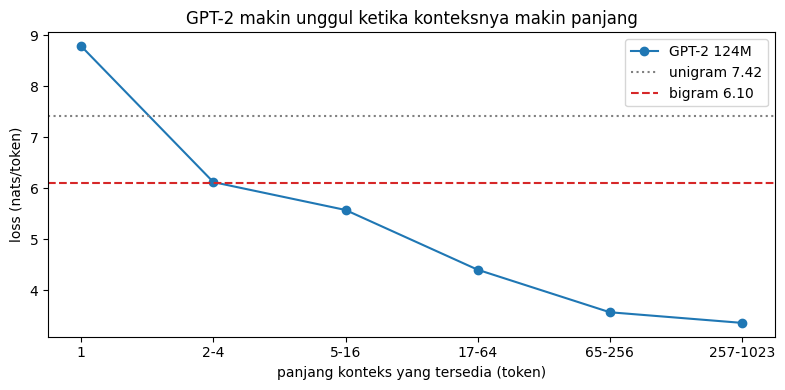

In [9]:
windows = [row.tolist() for row in test_windows]
per_position = torch.stack(token_nll(gpt2, windows, gpt2_tok.eos_token_id, batch_size=2)).numpy()
buckets = [(1, 1), (2, 4), (5, 16), (17, 64), (65, 256), (257, 1023)]
by_context = [float(per_position[:, lo - 1:hi].mean()) for lo, hi in buckets]

print(f"GPT-2, konteks penuh: {per_position.mean():.3f} nats/token (perplexity {math.exp(per_position.mean()):.1f}) "
      f"| bigram {nll_bigram:.3f} | unigram {nll_unigram:.3f}")
for (lo, hi), value in zip(buckets, by_context):
    print(f"  konteks {lo:>4}-{hi:<4} token: {value:.3f} nats (selisih vs bigram {value - nll_bigram:+.3f})")

labels = [str(lo) if lo == hi else f"{lo}-{hi}" for lo, hi in buckets]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(labels, by_context, marker="o", label="GPT-2 124M")
ax.axhline(nll_unigram, ls=":", c="gray", label=f"unigram {nll_unigram:.2f}")
ax.axhline(nll_bigram, ls="--", c="tab:red", label=f"bigram {nll_bigram:.2f}")
ax.set_xlabel("panjang konteks yang tersedia (token)")
ax.set_ylabel("loss (nats/token)")
ax.set_title("GPT-2 makin unggul ketika konteksnya makin panjang")
ax.legend()
plt.tight_layout()
plt.show()

Pada run historis (protokol yang sama dengan profil GPU: 8 jendela × 1.024 token), unigram mencapai 7,42 nats/token (perplexity ≈ 1.660), bigram 6,10 (≈ 448), dan GPT-2 dengan konteks penuh 3,49 (≈ 33). Kurvanya lebih informatif daripada rata-ratanya:

- **Konteks 1 token:** GPT-2 justru lebih buruk dari unigram (historis 8,79 nats). Jendela evaluasi dimulai di tengah artikel tanpa token pembuka, kondisi yang jarang ia temui saat dilatih.
- **Konteks 2–4 token:** GPT-2 kira-kira seri dengan bigram (historis: selisih +0,02 nats). Dengan bahan sependek ini, 124 juta parameter tidak memberi keunggulan atas tabel hitungan.
- **Konteks di atas 256 token:** GPT-2 unggul sekitar 2,75 nats, artinya perplexity e^2,75 ≈ 16 kali lebih rendah. Kurvanya masih turun setelah 256 token, jadi konteks yang jauh pun masih dipakai.

Jadi keunggulan transformer bukan tabel yang lebih pintar untuk konteks pendek, melainkan kemampuan memakai konteks panjang, hal yang sama yang memisahkan kalimat anjing dan truk. Batasnya: ini satu model, satu korpus, dan beberapa jendela uji.

## 2. Dari token ke vektor

Sebelum GPT-2 bisa membaca konteks, teks harus menjadi angka, lewat dua langkah. **Tokenisasi** memecah teks menjadi potongan yang ada di kosakata model. Lalu setiap token diganti dengan satu baris dari **tabel embedding**: vektor 768 bilangan yang menjadi koordinat token itu. Sel berikut melakukan keduanya pada kalimat anjing. Ini pekerjaan CPU: tokenizer berjalan di CPU, dan tabel embedding cukup dibaca barisnya.

In [10]:
sentence = RUNNING["anjing"] + " tired."
sent_token_ids = gpt2_tok(sentence)["input_ids"]
tokens = gpt2_tok.convert_ids_to_tokens(sent_token_ids)
print(f"{len(sentence.split())} kata -> {len(sent_token_ids)} token")
print(tokens)

wte = gpt2.transformer.wte.weight.detach().float().cpu()  # salinan CPU tabel embedding, hanya untuk lookup
n_gpt2 = sum(p.numel() for p in gpt2.parameters())
print(f"tabel embedding: {tuple(wte.shape)} = {wte.numel() / 1e6:.1f} jt parameter "
      f"({wte.numel() / n_gpt2:.1%} dari {n_gpt2 / 1e6:.1f} jt parameter GPT-2)")
dog = tokens.index("Ġdog")
print(f"vektor {tokens[dog]!r}: {wte.shape[1]} koordinat, lima pertama {np.round(wte[sent_token_ids[dog], :5].double().numpy(), 3).tolist()}")

for a, b in [(" dog", " puppy"), (" truck", " bus"), (" dog", " truck"), (" Monday", " Tuesday"), (" Monday", " banana")]:
    ia, ib = gpt2_tok(a)["input_ids"], gpt2_tok(b)["input_ids"]
    assert len(ia) == len(ib) == 1, (a, b)
    cos = torch.nn.functional.cosine_similarity(wte[ia[0]], wte[ib[0]], dim=0).item()
    print(f"  cos({a.strip():>7}, {b.strip():<8}) = {cos:.3f}")

15 kata -> 17 token
['The', 'Ġdog', 'Ġran', 'Ġaround', 'Ġthe', 'Ġpark', 'Ġall', 'Ġafternoon', ',', 'Ġso', 'Ġby', 'Ġevening', 'Ġit', 'Ġwas', 'Ġtoo', 'Ġtired', '.']
tabel embedding: (50257, 768) = 38.6 jt parameter (31.0% dari 124.4 jt parameter GPT-2)
vektor 'Ġdog': 768 koordinat, lima pertama [0.094, -0.077, 0.035, -0.035, -0.089]
  cos(    dog, puppy   ) = 0.621
  cos(  truck, bus     ) = 0.482
  cos(    dog, truck   ) = 0.334
  cos( Monday, Tuesday ) = 0.890
  cos( Monday, banana  ) = 0.283


Tiga hal dari output.

- **Token bukan kata.** 15 kata menjadi 17 token: setiap kata di kalimat ini cukup umum untuk punya token sendiri, sedangkan koma dan titik menjadi token terpisah. Karakter `Ġ` adalah cara GPT-2 menandai spasi di depan token. Kata yang jarang akan dipecah menjadi beberapa potongan, seperti yang terlihat di bagian 7.
- **Tabel embedding besar.** 50.257 baris × 768 kolom = 38,6 juta parameter, sekitar 31% dari 124,4 juta parameter GPT-2. Angka ini deterministik, sama di CPU maupun GPU.
- **Koordinat itu sudah bermakna.** **Cosine similarity** mengukur kemiripan arah dua vektor: 1 berarti searah, 0 berarti tidak berhubungan. Di run lokal (angkanya deterministik karena hanya membaca bobot), *Monday/Tuesday* 0,89 dan *dog/puppy* 0,62, sedangkan *dog/truck* 0,33 dan *Monday/banana* 0,28. Struktur makna sudah tertanam di tabel input, sebelum lapisan transformer mana pun bekerja.

Ada satu hal yang *tidak* bisa dilakukan tabel ini: vektor ` too` adalah baris yang sama di kalimat anjing maupun truk. Perbedaan tebakan GPT-2 di bagian 1 harus muncul di lapisan sesudahnya, yaitu attention.

## 3. Attention: cara setiap token membaca konteksnya

Mekanismenya bisa diikuti dengan kalimat anjing. Di posisi ` too`, model membentuk sebuah **query**, kira-kira pertanyaan "petunjuk apa yang saya butuhkan?". Setiap token sebelumnya menawarkan **key** (label isinya) dan **value** (isi yang bisa disalin). Kecocokan query dengan setiap key menjadi skor; softmax mengubah skor menjadi bobot positif yang berjumlah 1; hasilnya adalah campuran value yang ditimbang bobot itu. GPT-2 menjalankan 12 attention paralel per layer, disebut **head**, masing-masing di subruang 64 dimensi (12 × 64 = 768), dan ada 12 layer.

Deskripsi ini bisa dicek, tidak hanya dibaca. Sel berikut menghitung ulang bobot attention layer 0 dengan tangan dari bobot `c_attn` GPT-2, lalu membandingkannya dengan bobot yang dilaporkan model. Ini forward pass neural, jadi berjalan di GPU, dengan implementasi attention `eager` yang mengembalikan bobot attention secara eksplisit.

In [11]:
gpt2_eager = load_lm(GPT2_ID, attn_implementation="eager")
cfg = gpt2_eager.config
n_head, d_head = cfg.n_head, cfg.n_embd // cfg.n_head
x_sent = torch.tensor([sent_token_ids], device=DEVICE)
T = x_sent.shape[1]
assert_on_device(gpt2_eager, x_sent)

with torch.no_grad():
    out = gpt2_eager(input_ids=x_sent, output_attentions=True, output_hidden_states=True)
    block = gpt2_eager.transformer.h[0]
    h = block.ln_1(out.hidden_states[0])
    q, k, _ = block.attn.c_attn(h).split(cfg.n_embd, dim=-1)
    q, k = (t.view(1, T, n_head, d_head).transpose(1, 2) for t in (q, k))
    scores = q @ k.transpose(-1, -2) / math.sqrt(d_head)
    future = torch.triu(torch.ones(T, T, dtype=torch.bool, device=DEVICE), diagonal=1)
    attn_manual = scores.masked_fill(future, float("-inf")).softmax(-1)
attn_model = out.attentions[0]
max_diff = (attn_manual - attn_model).abs().max().item()
row_sum_err = (attn_model.sum(-1) - 1).abs().max().item()
future_mass = attn_model.masked_select(future).max().item()
print(f"kalimat: {T} token | {n_head} head x {d_head} dimensi = {n_head * d_head} = n_embd")
print(f"bobot attention layer 0: {tuple(attn_model.shape)} = (batch, head, query, key)")
print(f"tangan vs model: max|selisih| = {max_diff:.2e} | max|jumlah baris - 1| = {row_sum_err:.1e} | "
      f"bobot maksimum ke token sesudahnya = {future_mass:.1e}")
assert max_diff < 1e-4 and row_sum_err < 1e-4 and future_mass == 0.0

ckpt = hf_hub_download(GPT2_ID, "model.safetensors")
with safe_open(ckpt, "pt") as f:
    mask_keys = [key for key in f.keys() if re.fullmatch(r"(transformer\.)?h\.\d+\.attn\.bias", key)]
    mask0 = f.get_tensor(mask_keys[0])
side = mask0.shape[-1]
is_lower = torch.equal(mask0.reshape(side, side).bool(), torch.tril(torch.ones(side, side, dtype=torch.bool)))
mask_mb = len(mask_keys) * mask0.numel() * mask0.element_size() / 1e6
print(f"checkpoint: {len(mask_keys)} buffer mask {tuple(mask0.shape)} {mask0.dtype}, segitiga bawah: {is_lower} | "
      f"{mask_mb:.1f} MB dari file {os.path.getsize(ckpt) / 1e6:.1f} MB")

try:
    with torch.no_grad():
        att_default = gpt2(input_ids=x_sent, output_attentions=True).attentions
    returned = 0 if att_default is None else sum(a is not None for a in att_default)
    print(f"implementasi default {gpt2.config._attn_implementation!r}: {returned} dari {cfg.n_layer} layer "
          f"mengembalikan bobot attention")
except (ValueError, RuntimeError) as err:
    print(f"implementasi default {gpt2.config._attn_implementation!r} menolak output_attentions: {err}")

kalimat: 17 token | 12 head x 64 dimensi = 768 = n_embd
bobot attention layer 0: (1, 12, 17, 17) = (batch, head, query, key)
tangan vs model: max|selisih| = 0.00e+00 | max|jumlah baris - 1| = 1.8e-07 | bobot maksimum ke token sesudahnya = 0.0e+00
checkpoint: 12 buffer mask (1, 1, 1024, 1024) torch.float32, segitiga bawah: True | 50.3 MB dari file 548.1 MB
implementasi default 'sdpa': 0 dari 12 layer mengembalikan bobot attention


**Perhitungan tangan cocok dengan model.** Di CPU fp32 (run historis dan run lokal) selisihnya tepat 0; di GPU wajar muncul selisih sekitar 10⁻⁷ karena kernel matriksnya berbeda, dan sel ini berhenti bila selisihnya melebihi 10⁻⁴. Setiap baris berjumlah 1, jadi bobot attention memang distribusi peluang atas token konteks.

**"Setiap token terhadap setiap token lain" hanya separuh benar untuk GPT.** Bobot ke token sesudahnya tepat 0: **mask kausal** hanya mengizinkan setiap posisi membaca dirinya dan token sebelumnya, karena model generatif tidak boleh mengintip token yang sedang ia tebak. Attention dua arah adalah ciri encoder seperti BERT. Mask itu bahkan tersimpan di checkpoint GPT-2: di run lokal penyusun, 12 matriks segitiga bawah 1.024 × 1.024 float32, total 50,3 MB dari file 548,1 MB.

**Perilaku pustaka bisa berubah tanpa suara.** Baris terakhir mencetak berapa layer yang mengembalikan bobot attention dengan implementasi default (`sdpa`, kernel attention terfusi). Di run historis maupun run lokal (transformers 5.20.2), jawabannya 0 dari 12, tanpa error dan tanpa peringatan; versi lain bisa beralih ke eager atau melempar error. Karena itu notebook ini menulis `attn_implementation="eager"` secara eksplisit setiap kali butuh bobot attention.

Satu kalimat terlalu kecil untuk melihat apa yang dikerjakan 144 head. Sel berikut menjalankan potongan wikitext (GPU) dan mengukur tiga hal per head: fraksi bobot ke token tepat sebelumnya, fraksi bobot ke token pertama, dan jarak rata-rata yang dibaca setelah token pertama dikeluarkan.

teks: 512 token | 12 layer x 12 head = 144 head
previous-token head (>50% bobot ke token sebelumnya): 2 -> (layer, head, fraksi) [(2, 2, 0.56), (4, 11, 0.99)]
attention-sink head (>50% bobot ke token pertama): 50 dari 144
bobot rata-rata ke token pertama, per layer: [0.01, 0.04, 0.14, 0.32, 0.37, 0.55, 0.5, 0.59, 0.55, 0.59, 0.52, 0.45]
jarak baca rata-rata tanpa sink, per layer  : [42.7, 72.5, 29.8, 23.0, 30.1, 55.9, 45.2, 70.1, 55.7, 83.2, 95.5, 105.7]


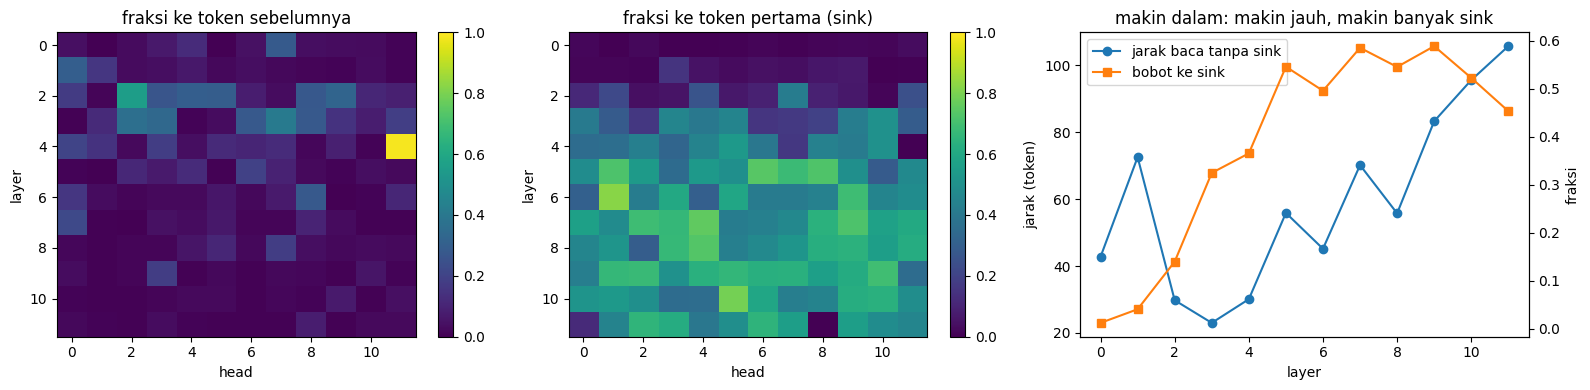

In [12]:
x_census = torch.tensor([wiki_ids["test"][:PROFILE["census_tokens"]].tolist()], device=DEVICE)
with torch.no_grad():
    A = torch.stack(gpt2_eager(input_ids=x_census, output_attentions=True).attentions)[:, 0]
nL, nH, nT, _ = A.shape
t = torch.arange(1, nT, device=DEVICE)
prev_frac = A[:, :, t, t - 1].mean(-1)
sink_frac = A[:, :, 1:, 0].mean(-1)
positions = torch.arange(nT, device=DEVICE)
gap = (positions[:, None] - positions[None, :]).clamp(min=0).float()
B = A[:, :, 1:, 1:]
B = B / B.sum(-1, keepdim=True).clamp(min=1e-9)
dist = (B * gap[1:, 1:]).sum(-1).mean(-1)
prev_frac, sink_frac, dist = (require_finite(v, "sensus").cpu() for v in (prev_frac, sink_frac, dist))

prev_heads = [(int(l), int(hh), round(prev_frac[l, hh].item(), 2)) for l, hh in (prev_frac > 0.5).nonzero()]
print(f"teks: {nT} token | {nL} layer x {nH} head = {nL * nH} head")
print(f"previous-token head (>50% bobot ke token sebelumnya): {len(prev_heads)} -> (layer, head, fraksi) {prev_heads}")
print(f"attention-sink head (>50% bobot ke token pertama): {int((sink_frac > 0.5).sum())} dari {nL * nH}")
print("bobot rata-rata ke token pertama, per layer:", np.round(sink_frac.mean(1).double().numpy(), 2).tolist())
print("jarak baca rata-rata tanpa sink, per layer  :", np.round(dist.mean(1).double().numpy(), 1).tolist())

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for ax, mat, title in [(axs[0], prev_frac, "fraksi ke token sebelumnya"), (axs[1], sink_frac, "fraksi ke token pertama (sink)")]:
    im = ax.imshow(mat.numpy(), cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xlabel("head")
    ax.set_ylabel("layer")
    ax.set_title(title)
    fig.colorbar(im, ax=ax)
axs[2].plot(range(nL), dist.mean(1).numpy(), marker="o", label="jarak baca tanpa sink")
axs[2].set_xlabel("layer")
axs[2].set_ylabel("jarak (token)")
ax2 = axs[2].twinx()
ax2.plot(range(nL), sink_frac.mean(1).numpy(), marker="s", c="tab:orange", label="bobot ke sink")
ax2.set_ylabel("fraksi")
axs[2].set_title("makin dalam: makin jauh, makin banyak sink")
h1, l1 = axs[2].get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
axs[2].legend(h1 + h2, l1 + l2, loc="upper left")
plt.tight_layout()
plt.show()

del gpt2_eager, A, B
free_memory()

Pada run historis (512 token, CPU fp32) tiga pola muncul:

- **Previous-token head jarang.** Hanya 2 dari 144 head yang menaruh lebih dari separuh bobotnya ke token tepat sebelumnya; satu di antaranya (layer 4, head 11) hampir murni, 0,99.
- **Sepertiga head adalah attention sink.** 50 dari 144 head menaruh lebih dari separuh bobotnya di token pertama, dan rata-ratanya naik dari 0,01 di layer 0 ke sekitar 0,5–0,6 di layer tengah. Token pertama tidak istimewa isinya. Softmax memaksa bobot dialokasikan ke suatu tempat, dan head yang tidak menemukan apa pun yang berguna memarkirnya di posisi 0 (Xiao dkk., 2023, menamainya *attention sink*).
- **Makin dalam, makin jauh, tapi tidak monoton.** Setelah sink dikeluarkan, layer 2–4 membaca rata-rata 23–30 token ke belakang dan dua layer terakhir sekitar 100 token; layer 1 adalah pengecualian (sekitar 72).

Pelajaran terpentingnya: **bobot attention bukan penjelasan kausal.** Sepertiga head menaruh bobot besar pada token yang tidak bermakna, jadi bobot besar tidak berarti "token ini menyebabkan jawabannya". Untuk tahu mengapa GPT-2 memilih *tired* untuk anjing, dibutuhkan eksperimen intervensi, misalnya mengganti *dog* lalu melihat Δ berubah, bukan sekadar membaca peta bobot.

## 4. Skala: apa arti *large*

*Large* berarti dua hal: jumlah parameter, dan sumber daya untuk menjalankannya. Mulai dari GPT-2 yang sudah dipakai. Setiap parameter fp32 butuh 4 byte, jadi memori bobotnya bisa diperkirakan dengan satu perkalian; itu **estimasi analitis**. Di GPU, sel berikut juga **mengukur** memori yang benar-benar terpakai ketika bobot dimuat dan ketika satu forward pass 1.024 token berjalan.

In [13]:
analytic_mb = n_gpt2 * 4 / 1e6
print(f"GPT-2: {n_gpt2:,} parameter x 4 byte = {analytic_mb:.1f} MB  [estimasi analitis, fp32]")
print(f"file checkpoint {os.path.getsize(ckpt) / 1e6:.1f} MB = bobot + buffer mask {mask_mb:.1f} MB + metadata")

if DEVICE.type == "cuda":
    free_memory()
    before = torch.cuda.memory_allocated()
    probe = load_lm(GPT2_ID)
    weights_mb = (torch.cuda.memory_allocated() - before) / 1e6
    after_load = torch.cuda.memory_allocated()
    torch.cuda.reset_peak_memory_stats()
    with torch.no_grad():
        probe(input_ids=torch.tensor(windows[:1], device=DEVICE))
    sync()
    extra_mb = (torch.cuda.max_memory_allocated() - after_load) / 1e6
    print(f"terukur di GPU: bobot {weights_mb:.1f} MB | tambahan puncak saat forward 1 x 1.024 token: {extra_mb:.1f} MB")
    del probe
    free_memory()
else:
    print("memori GPU tidak diukur: profil CPU")

GPT-2: 124,439,808 parameter x 4 byte = 497.8 MB  [estimasi analitis, fp32]
file checkpoint 548.1 MB = bobot + buffer mask 50.3 MB + metadata
terukur di GPU: bobot 498.6 MB | tambahan puncak saat forward 1 x 1.024 token: 284.5 MB


In [14]:
# Estimasi analitis saja: tidak ada model besar yang diunduh atau dimuat.
sizes = {"GPT-2 124M": n_gpt2, "7B": 7e9, "70B": 70e9, "175B (GPT-3)": 175e9, "405B": 405e9}
bytes_per_param = {"fp32": 4, "fp16/bf16": 2, "int8": 1, "int4": 0.5, "latih AdamW": 16}
rows = []
for name, n in sizes.items():
    row = {"model": name}
    row.update({col: n * b / 1e9 for col, b in bytes_per_param.items()})
    row[f"16-bit / {MEMORY_LABEL}"] = n * 2 / 1e9 / MEMORY_GB
    rows.append(row)
print(f"satuan GB; {MEMORY_LABEL} perangkat ini = {MEMORY_GB:.1f} GB")
print(pd.DataFrame(rows).set_index("model").round(1).to_string())
print("latih AdamW = 16 byte/parameter (bobot + gradien 16-bit, salinan master fp32, dua momen Adam fp32), belum termasuk aktivasi")

satuan GB; VRAM GPU perangkat ini = 15.6 GB
                fp32  fp16/bf16   int8   int4  latih AdamW  16-bit / VRAM GPU
model                                                                        
GPT-2 124M       0.5        0.2    0.1    0.1          2.0                0.0
7B              28.0       14.0    7.0    3.5        112.0                0.9
70B            280.0      140.0   70.0   35.0       1120.0                9.0
175B (GPT-3)   700.0      350.0  175.0   87.5       2800.0               22.4
405B          1620.0      810.0  405.0  202.5       6480.0               51.8
latih AdamW = 16 byte/parameter (bobot + gradien 16-bit, salinan master fp32, dua momen Adam fp32), belum termasuk aktivasi


Estimasinya 124.439.808 parameter × 4 byte ≈ 497,8 MB. Angka bobot yang terukur di GPU seharusnya hampir sama; selisih kecil berasal dari blok memori yang dibulatkan oleh alokator PyTorch. Yang lebih menarik adalah tambahan memori saat forward pass. Logit untuk 1.024 posisi × 50.257 token × 4 byte saja sudah sekitar 206 MB, jadi menjalankan model selalu butuh lebih dari bobotnya.

Tabel kedua memperbesar perkalian yang sama, dan semua barisnya kecuali GPT-2 adalah estimasi. Model 7B dalam 16-bit butuh 14 GB hanya untuk bobot, hampir seluruh memori T4 (sekitar 15 GB). Melatihnya dengan AdamW butuh sekitar 112 GB sebelum aktivasi dihitung. Model 405B butuh 810 GB untuk bobot 16-bit saja. Kolom int8 dan int4 adalah alasan pola pruning dan quantization (Bab 12–13) ada di katalog buku.

Sebelum membandingkan ukuran model, ada satu jebakan presisi. Checkpoint Pythia disimpan dalam float16, dan transformers 5 memuat model mengikuti tipe di checkpoint bila `dtype` tidak ditulis; transformers 4 dulu memuat float32. Sel berikut memuat model Pythia yang sama tiga kali (tanpa `dtype`, float32 eksplisit, dan half precision yang cocok untuk GPU ini: fp16 di T4, bf16 di GPU Ampere ke atas), lalu mengukur loss dan waktu forward 512 token. Waktu diambil di antara dua `synchronize`, karena tanpa itu Python hanya mencatat waktu mengirim perintah ke GPU.

In [15]:
py_tok = AutoTokenizer.from_pretrained(PYTHIA_TOKENIZER_ID)
probe_ids = py_tok(wiki["test"][:20000])["input_ids"][:512]


def timed_loss(model, ids, repeats=5):
    x = torch.tensor([ids], device=DEVICE)
    assert_on_device(model, x)
    times = []
    with torch.no_grad():
        model(input_ids=x[:, :32])  # pemanasan
        for _ in range(repeats):
            sync()
            t0 = time.perf_counter()
            loss = model(input_ids=x, labels=x).loss
            sync()
            times.append(time.perf_counter() - t0)
    return float(np.median(times)), require_finite(loss.float(), "loss").item()


dtype_runs = {}
for label, kwargs in [("tanpa dtype", {}), ("float32 eksplisit", {"dtype": torch.float32}),
                      (f"{str(HALF_DTYPE).split('.')[-1]} eksplisit", {"dtype": HALF_DTYPE})]:
    m = AutoModelForCausalLM.from_pretrained(PROFILE["dtype_probe_model"], **kwargs).to(DEVICE).eval()
    seconds, loss = timed_loss(m, probe_ids)
    dtype_runs[label] = (str(m.dtype), seconds, loss)
    print(f"{label:<20} dimuat sebagai {str(m.dtype):<15} | median {seconds * 1000:8.1f} ms per forward 512 token | loss {loss:.5f}")
    del m
    free_memory()
fp32_loss = dtype_runs["float32 eksplisit"][2]
for label, (loaded, seconds, loss) in dtype_runs.items():
    print(f"  {label:<20} selisih loss vs float32: {abs(loss - fp32_loss):.5f} nats")

tanpa dtype          dimuat sebagai torch.float16   | median     17.4 ms per forward 512 token | loss 3.27309
float32 eksplisit    dimuat sebagai torch.float32   | median     44.8 ms per forward 512 token | loss 3.26199
float16 eksplisit    dimuat sebagai torch.float16   | median     13.8 ms per forward 512 token | loss 3.27309
  tanpa dtype          selisih loss vs float32: 0.01110 nats
  float32 eksplisit    selisih loss vs float32: 0.00000 nats
  float16 eksplisit    selisih loss vs float32: 0.01110 nats


Dua hal untuk dibaca. Pertama, **loss bergeser sedikit** di half precision; pada run historis CPU selisihnya sekitar 0,0014 nats untuk Pythia-160m, dan di run lokal `cpu_smoke` 0,0185 nats untuk Pythia-70m (transformers 5.20 memang memuatnya sebagai float16 bila `dtype` tidak ditulis). Kecil, tetapi cukup untuk mengaburkan perbandingan yang halus, sehingga semua pengukuran loss di notebook ini memakai float32 eksplisit; modelnya kecil, jadi memorinya terjangkau. Kedua, **kecepatan bergantung perangkat**. Di CPU, float16 justru lebih lambat (run historis 6–8 kali, run lokal 4–5 kali) karena CPU tidak punya jalur cepat untuk matmul float16. Di GPU, half precision biasanya setara atau lebih cepat, tetapi untuk model sekecil ini satu forward hanya beberapa milidetik dan banyak dipengaruhi overhead, jadi angka ini bukan benchmark kecepatan. Pelajarannya: tulis `dtype` secara eksplisit, karena default pustaka bisa berubah antarversi.

Sekarang klaim utama bagian ini. Buku mengutip Kaplan dkk. (2020): loss turun mengikuti **hukum pangkat** terhadap ukuran model, L(N) ∝ N^(−α), dengan N jumlah parameter non-embedding dan α ≈ 0,076 di paper itu. Hukum pangkat tampak sebagai garis lurus di grafik log-log, dan α adalah kemiringannya.

Suite Pythia cocok untuk mengujinya karena semua ukurannya dilatih dengan data dan urutan yang sama; yang berubah hanya ukuran. Sel berikut menghitung loss beberapa model Pythia pada potongan wikitext test yang sama, di GPU, dalam float32.

pythia-14m   total   14.1M | non-embedding    1.19M |  6 layer x d128   | loss 5.1216 |   4.3 s
pythia-31m   total   30.5M | non-embedding    4.74M |  6 layer x d256   | loss 4.5960 |   4.8 s
pythia-70m   total   70.4M | non-embedding   18.92M |  6 layer x d512   | loss 4.2861 |   5.4 s
pythia-160m  total  162.3M | non-embedding   85.06M | 12 layer x d768   | loss 3.7020 |   1.6 s
pythia-410m  total  405.3M | non-embedding  302.31M | 24 layer x d1024  | loss 3.2045 |  14.9 s
fit: L(N) = 16.50 * N^(-0.0826) | residual per model (%): [-1.46, -0.87, 3.52, 1.34, -2.65]
Kaplan dkk. (2020): alpha_N ~ 0.076 | terukur di sini: 0.0826 dari 5 titik


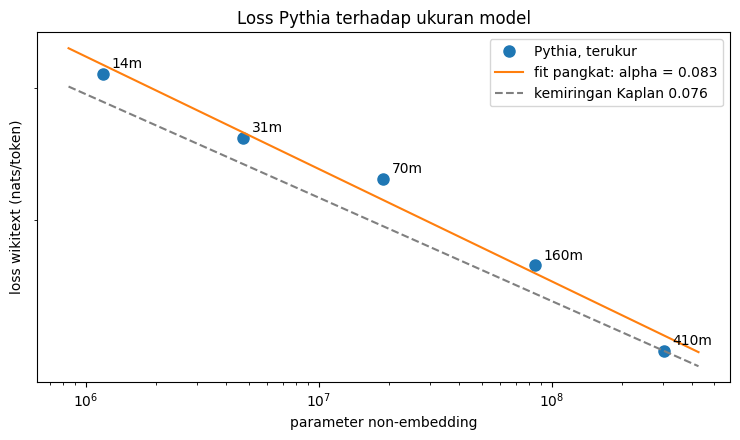

In [16]:
py_test_ids = py_tok(wiki["test"])["input_ids"]
WIN = 512
chunks = [py_test_ids[i * WIN:(i + 1) * WIN] for i in range(PROFILE["scaling_windows"])]
scaling = []
for short in PROFILE["scaling_models"]:
    t0 = time.perf_counter()
    m = load_lm(f"EleutherAI/{short}")
    emb = {id(m.get_input_embeddings().weight), id(m.get_output_embeddings().weight)}
    n_total = sum(p.numel() for p in m.parameters())
    n_nonemb = n_total - sum(p.numel() for p in m.parameters() if id(p) in emb)
    loss = float(torch.cat(token_nll(m, chunks, py_tok.eos_token_id, batch_size=4)).mean())
    scaling.append((short, n_total, n_nonemb, loss))
    print(f"{short:<12} total {n_total / 1e6:6.1f}M | non-embedding {n_nonemb / 1e6:7.2f}M | "
          f"{m.config.num_hidden_layers:>2} layer x d{m.config.hidden_size:<5} | loss {loss:.4f} | {time.perf_counter() - t0:5.1f} s")
    del m
    free_memory()

N = np.array([s[2] for s in scaling], dtype=float)
L = np.array([s[3] for s in scaling])
slope, intercept = np.polyfit(np.log(N), np.log(L), 1)
alpha = -slope
resid = 100 * (L - np.exp(intercept) * N ** slope) / L
print(f"fit: L(N) = {np.exp(intercept):.2f} * N^(-{alpha:.4f}) | residual per model (%): {np.round(resid, 2).tolist()}")
print(f"Kaplan dkk. (2020): alpha_N ~ 0.076 | terukur di sini: {alpha:.4f} dari {len(N)} titik")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
xs = np.logspace(np.log10(N.min()) - 0.15, np.log10(N.max()) + 0.15, 50)
ax.plot(N, L, "o", ms=8, label="Pythia, terukur")
ax.plot(xs, np.exp(intercept) * xs ** slope, "-", label=f"fit pangkat: alpha = {alpha:.3f}")
ax.plot(xs, L[-1] * (xs / N[-1]) ** -0.076, "--", c="gray", label="kemiringan Kaplan 0.076")
for short, _, n, loss in scaling:
    ax.annotate(short.split("-")[1], (n, loss), textcoords="offset points", xytext=(6, 4))
ax.set_xscale("log")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(matplotlib.ticker.ScalarFormatter())
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_xlabel("parameter non-embedding")
ax.set_ylabel("loss wikitext (nats/token)")
ax.set_title("Loss Pythia terhadap ukuran model")
ax.legend()
plt.tight_layout()
plt.show()

Pada run historis (lima model, 16 × 512 token), parameter non-embedding membentang 254 kali lipat, dari 1,19 juta (14m) sampai 302 juta (410m). Loss turun dari 5,12 ke 3,20 nats/token, dan kelima titik hampir segaris dengan **α terukur 0,083**, dekat dengan 0,076 milik Kaplan walaupun data latih, tokenizer, dan teks evaluasinya berbeda. Residual terbesar sekitar 3,5%.

Seberapa jauh angka ini boleh dibawa? Lima titik dari satu keluarga model, satu teks evaluasi, dan model kecil yang dilatih jauh melewati titik optimal-komputasinya cukup untuk melihat *bentuk* hukum pangkat, tetapi tidak cukup untuk menetapkan eksponen bagi model lain atau memprediksi model ratusan miliar parameter. Profil `cpu_smoke` hanya punya tiga titik, sehingga fit-nya hampir pasti terlihat bagus.

Ada juga koreksi kecil terhadap rumusan buku, yang menyebut perplexity *atau akurasi* membaik mengikuti hukum pangkat. Yang terukur mulus di sini adalah loss, dan perplexity ikut karena perplexity = e^loss. Akurasi pada tugas tertentu tidak wajib ikut mulus; bagian berikut memperlihatkannya dengan model-model yang sama.

## 5. Few-shot: tugas baru dari beberapa contoh

Model klasik butuh ribuan contoh berlabel untuk setiap tugas. Buku menggambarkan LLM yang cukup diberi instruksi (**zero-shot**) atau beberapa contoh di dalam prompt (**few-shot**), tanpa mengubah bobot sama sekali. Contoh-contoh di prompt itu disebut **demonstrasi**.

Caranya memakai mesin yang sama dengan kalimat anjing: model hanya menebak token berikutnya. Prompt diakhiri `Sentiment:`, dan prediksi diambil dari logit mana yang lebih besar, ` positive` atau ` negative`. Data ujinya ulasan film SST-2.

Ada satu jebakan sebelum menyusun prompt. Prompt few-shot terdiri dari awalan yang sama ditambah ulasan yang berganti-ganti, sehingga ada godaan untuk menokenisasi awalan sekali saja lalu menyambung token-tokennya. Sel berikut memeriksa apakah itu aman, hanya dengan tokenizer di CPU.

In [17]:
INSTR = "Classify the sentiment of each movie review as positive or negative.\n\n"


def fmt_query(review):
    return f"Review: {review}\nSentiment:"


def fmt_demo(review, label):
    return fmt_query(review) + (" positive" if label else " negative") + "\n\n"


example_prefix = INSTR + fmt_demo("a gorgeous, witty film", 1)
alone = py_tok(example_prefix)["input_ids"]
joined = py_tok(example_prefix + fmt_query("dull and lifeless"))["input_ids"]
print("awalan ditokenisasi sendiri, 3 token terakhir:", py_tok.convert_ids_to_tokens(alone[-3:]))
print("di dalam prompt utuh, token di sekitar sambungan:", py_tok.convert_ids_to_tokens(joined[len(alone) - 2:len(alone) + 2]))
print("token awalan = awal token prompt utuh?", joined[:len(alone)] == alone)

awalan ditokenisasi sendiri, 3 token terakhir: [':', 'Ġpositive', 'ĊĊ']
di dalam prompt utuh, token di sekitar sambungan: ['Ġpositive', 'Ċ', 'Ċ', 'Review']
token awalan = awal token prompt utuh? False


Tidak aman. Teks awalannya sama persis, tetapi bila ditokenisasi sendiri, dua baris baru di ujungnya menjadi satu token gabungan `ĊĊ`; di dalam prompt utuh, keduanya menjadi dua token `Ċ` yang disusul `Review`. Tokenizer memilih potongan dengan melihat teks di sebelah kanannya, jadi titik sambungan bisa mengubah token. Model menerima input yang berbeda; pada run historis, logitnya bergeser sampai 0,23 nats karena hal ini. Notebook ini selalu menokenisasi prompt utuh, jadi masalah itu tidak muncul.

Protokolnya: instruksi, lalu nol atau empat demonstrasi (dua positif dan dua negatif dari split train, urutannya diacak), lalu ulasan uji. Ada tiga set demonstrasi acak yang berbeda. Untuk setiap konfigurasi dicatat:

- **akurasi**: fraksi ulasan yang ditebak benar; menebak acak memberi sekitar 0,5;
- **pos-rate**: fraksi prediksi positif; karena label uji seimbang, model yang tidak bias seharusnya dekat 0,5;
- **akurasi terkalibrasi**: setelah **kalibrasi kontekstual** (Zhao dkk., 2021). Model diberi prompt yang sama dengan ulasan tanpa isi (`N/A`, string kosong, `[MASK]`). Peluang label untuk input kosong itu dianggap bias bawaan prompt, lalu dipakai untuk membagi peluang di setiap ulasan.

Sel berikut menyiapkan data dan prompt (CPU); sel sesudahnya menilai semua prompt di GPU.

In [18]:
sst_val = load_dataset("stanfordnlp/sst2", split="validation")
sst_train = load_dataset("stanfordnlp/sst2", split="train")
rng = random.Random(0)
val_labels = list(sst_val["label"])
pos_i = [i for i, y in enumerate(val_labels) if y == 1]
neg_i = [i for i, y in enumerate(val_labels) if y == 0]
k = PROFILE["fewshot_per_label"]
EVAL = [(sst_val[i]["sentence"].strip(), sst_val[i]["label"]) for i in rng.sample(pos_i, k) + rng.sample(neg_i, k)]
Y = torch.tensor([y for _, y in EVAL])


def demo_set(seed, k=4):
    r = random.Random(100 + seed)
    pool = [i for i in r.sample(range(len(sst_train)), 4000) if len(sst_train[i]["sentence"].split()) <= 25]
    pos = [i for i in pool if sst_train[i]["label"] == 1][:k // 2]
    neg = [i for i in pool if sst_train[i]["label"] == 0][:k // 2]
    demos = [(sst_train[i]["sentence"].strip(), sst_train[i]["label"]) for i in pos + neg]
    r.shuffle(demos)
    return demos


PREFIXES = {"0-shot": INSTR}
for seed in range(3):
    PREFIXES[f"4-shot set-{seed}"] = INSTR + "".join(fmt_demo(s, y) for s, y in demo_set(seed))
CONTENT_FREE = ["N/A", "", "[MASK]"]
assert all(len(py_tok(w)["input_ids"]) == 1 for w in [" negative", " positive"])
LABEL_IDS = [py_tok(" negative")["input_ids"][0], py_tok(" positive")["input_ids"][0]]
print(f"{len(EVAL)} ulasan uji ({k} positif, {k} negatif) | {len(PREFIXES)} konfigurasi prompt")
print("contoh prompt 4-shot set-0:\n" + PREFIXES["4-shot set-0"] + fmt_query(EVAL[0][0]))

160 ulasan uji (80 positif, 80 negatif) | 4 konfigurasi prompt
contoh prompt 4-shot set-0:
Classify the sentiment of each movie review as positive or negative.

Review: works - mostly due to its superior cast
Sentiment: positive

Review: easily the most thoughtful fictional examination of the root
Sentiment: positive

Review: , it 's too long and unfocused .
Sentiment: negative

Review: as telling a country skunk
Sentiment: negative

Review: ( serry ) wants to blend politics and drama , an admirable ambition .
Sentiment:


In [19]:
fewshot = []
for short in PROFILE["fewshot_models"]:
    m = load_lm(f"EleutherAI/{short}")
    for config, prefix in PREFIXES.items():
        seqs = [py_tok(prefix + fmt_query(s))["input_ids"] for s, _ in EVAL]
        logits = last_token_logits(m, seqs, py_tok.eos_token_id, token_ids=LABEL_IDS)
        pred = logits.argmax(1)
        free_seqs = [py_tok(prefix + fmt_query(s))["input_ids"] for s in CONTENT_FREE]
        bias = last_token_logits(m, free_seqs, py_tok.eos_token_id, token_ids=LABEL_IDS).softmax(1).mean(0)
        pred_cal = (logits.softmax(1) / bias).argmax(1)
        fewshot.append({"model": short, "konfigurasi": config,
                        "akurasi": (pred == Y).float().mean().item(),
                        "pos_rate": pred.float().mean().item(),
                        "akurasi_kalibrasi": (pred_cal == Y).float().mean().item()})
    del m
    free_memory()

fs = pd.DataFrame(fewshot)
print(fs.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
four = fs[fs["konfigurasi"] != "0-shot"]
print(f"4-shot: akurasi {four['akurasi'].min():.3f}-{four['akurasi'].max():.3f} | "
      f"pos-rate {four['pos_rate'].min():.2f}-{four['pos_rate'].max():.2f} | "
      f"terkalibrasi {four['akurasi_kalibrasi'].min():.3f}-{four['akurasi_kalibrasi'].max():.3f}")

      model  konfigurasi  akurasi  pos_rate  akurasi_kalibrasi
 pythia-70m       0-shot    0.706     0.519              0.706
 pythia-70m 4-shot set-0    0.500     0.000              0.581
 pythia-70m 4-shot set-1    0.506     0.031              0.506
 pythia-70m 4-shot set-2    0.500     0.087              0.512
pythia-160m       0-shot    0.506     0.981              0.681
pythia-160m 4-shot set-0    0.519     0.894              0.506
pythia-160m 4-shot set-1    0.663     0.625              0.506
pythia-160m 4-shot set-2    0.500     0.000              0.494
pythia-410m       0-shot    0.681     0.781              0.681
pythia-410m 4-shot set-0    0.531     0.031              0.744
pythia-410m 4-shot set-1    0.525     0.975              0.694
pythia-410m 4-shot set-2    0.519     0.019              0.544
4-shot: akurasi 0.500-0.663 | pos-rate 0.00-0.98 | terkalibrasi 0.494-0.744


Pada run historis (tiga ukuran Pythia, 160 ulasan), polanya berlawanan dengan gambaran "beri beberapa contoh, model langsung bisa":

- **Empat demonstrasi sering memperburuk.** Akurasi 4-shot berkisar 0,50–0,67, kebanyakan di sekitar 0,50, setara menebak. Instruksi tanpa demo justru lebih baik pada 70m (0,71) dan 410m (0,68).
- **Prediksi kolaps ke satu label, dan labelnya bergantung pada set demo.** pos-rate 4-shot berayun dari 0,00 sampai 0,98. Pythia-410m menyebut 3% ulasan positif dengan set-0 dan 98% dengan set-1, padahal kedua set sama-sama berisi dua demo positif dan dua negatif.
- **Sinyalnya ada, tertutup bias.** Kalibrasi menaikkan 410m set-0 dari 0,53 ke 0,74, tetapi di konfigurasi lain bisa menurunkan (160m set-1: 0,67 → 0,51).

Notebook asli memakai KV cache dengan awalan yang ditokenisasi secara kanonik; notebook ini menilai prompt utuh. Tokennya sama, tetapi urutan penjumlahan float berbeda, jadi satu-dua ulasan yang hampir seri bisa berpindah label (masing-masing 1/160 ≈ 0,006 akurasi).

Artinya: pada model 70M–410M dengan format prompt ini, few-shot rapuh dan bias label mendominasi. Itu tidak membantah laporan few-shot pada model yang jauh lebih besar; paper GPT-3 melaporkan jarak few-shot terhadap zero-shot melebar seiring ukuran model, dan eksperimen ini tidak bisa menguji model sebesar itu. Bersama bagian 4, gambarnya jelas: loss turun mulus seiring ukuran, sementara akurasi few-shot mentah di skala ini tetap dekat peluang.

## 6. Generasi: lancar tidak sama dengan benar

Buku menyebut LLM menghasilkan teks yang lancar di berbagai gaya. Kelancaran itu bergantung pada sesuatu yang tidak dibahas bab ini: cara token dipilih saat **decoding**. Mesinnya tetap sama, model memberi peluang untuk token berikutnya, tetapi kita bisa selalu mengambil token paling mungkin (**greedy**) atau mengambil sampel acak dari token teratas yang peluang kumulatifnya 90% (**nucleus sampling**, p = 0,9).

GPT-2 diminta melanjutkan tiga prompt dengan kedua cara, di GPU. Repetisi diukur dengan **distinct-2** (fraksi pasangan token yang unik; 1 berarti tidak ada pasangan yang berulang) dan fraksi 4-gram yang berulang.

In [20]:
GEN_PROMPTS = ["The history of the Roman Empire",
               "In a shocking finding, scientists discovered",
               "The best way to learn programming is"]


def distinct_n(ids, n):
    grams = [tuple(ids[i:i + n]) for i in range(len(ids) - n + 1)]
    return len(set(grams)) / max(len(grams), 1)


for strategy, kwargs in [("greedy", {"do_sample": False}), ("nucleus p=0.9", {"do_sample": True, "top_p": 0.9, "top_k": 0})]:
    d2, rep4 = [], []
    for i, prompt in enumerate(GEN_PROMPTS):
        torch.manual_seed(i)
        enc = gpt2_tok(prompt, return_tensors="pt").to(DEVICE)
        assert_on_device(gpt2, enc["input_ids"])
        with torch.no_grad():
            out = gpt2.generate(**enc, max_new_tokens=PROFILE["gen_tokens"], pad_token_id=gpt2_tok.eos_token_id, **kwargs)
        new_ids = out[0, enc["input_ids"].shape[1]:].tolist()
        d2.append(distinct_n(new_ids, 2))
        rep4.append(1 - distinct_n(new_ids, 4))
        if i == 0:
            print(f"[{strategy}] {prompt}{gpt2_tok.decode(new_ids[:50])!r}")
    print(f"{strategy:<14} distinct-2 {np.mean(d2):.3f} | fraksi 4-gram berulang {np.mean(rep4):.3f} (rata-rata 3 prompt)\n")

[greedy] The history of the Roman Empire' is a fascinating one. The Roman Empire was founded by the Romans, and the Roman Empire was founded by the Romans. The Romans were the first to establish a state of war, and the Romans were the first to establish a state of peace. The'
greedy         distinct-2 0.367 | fraksi 4-gram berulang 0.558 (rata-rata 3 prompt)

[nucleus p=0.9] The history of the Roman Empire' was nothing short of brutal. Succession to Rome finally came in 954 B.C., making the Empire the first Western power to offer Christianity to Muslims. But Rome could not win. By the time the emperor returned, his legitimacy had been taken'
nucleus p=0.9  distinct-2 0.975 | fraksi 4-gram berulang 0.000 (rata-rata 3 prompt)



Pada run historis (80 token, rata-rata tiga prompt), greedy menghasilkan kalimat gramatikal yang berputar di tempat. *The Roman Empire was founded by the Romans* muncul dua kali berturut-turut; 55,8% 4-gram adalah pengulangan dan distinct-2 hanya 0,37. Nucleus sampling menghapus pengulangan (distinct-2 0,92; 1,3% 4-gram berulang) dan tetap lancar, tetapi isinya karangan, misalnya *Aeolian Caliphate* yang tidak pernah ada.

Teks greedy deterministik, jadi di GPU seharusnya sama atau hampir sama dengan run historis. Teks nucleus bergantung pada generator acak perangkat, jadi isinya akan berbeda; yang layak dibandingkan hanya pola angkanya. Dua pelajaran: kelancaran adalah hasil bersama model dan strategi decoding (Holtzman dkk., 2020), dan decoding yang paling enak dibaca justru paling bebas mengarang. Jurang antara fasih dan faktual inilah alasan kelompok pola RAG (Bab 26–29) ada di katalog. Tiga prompt dan satu model kecil tidak cukup untuk mengukur tingkat halusinasi; ini contoh, bukan benchmark.

## 7. Multibahasa: makna sama, biaya berbeda

Buku mencatat bahwa kemampuan LLM timpang antarbahasa, terbaik pada bahasa yang dominan di data latih. Untuk pembaca berbahasa Indonesia, ketimpangan itu bisa dihitung. Mulai dari kalimat anjing dan terjemahannya: berapa token yang dibutuhkan tokenizer GPT-2, yang dilatih hampir hanya pada teks Inggris, dan tokenizer BLOOM, yang dilatih pada korpus multibahasa yang memuat bahasa Indonesia? Ini pekerjaan tokenizer, jadi CPU.

In [21]:
TOKENIZERS = {GPT2_ID: gpt2_tok, PYTHIA_TOKENIZER_ID: py_tok}
for rid in [QWEN_TOKENIZER_ID, BLOOM_ID]:
    TOKENIZERS[rid] = AutoTokenizer.from_pretrained(rid)

running_pair = {"EN": sentence,
                "ID": "Anjing itu berlari di taman sepanjang sore, jadi menjelang malam ia terlalu lelah."}
for rid in [GPT2_ID, BLOOM_ID]:
    tk = TOKENIZERS[rid]
    for lang, text in running_pair.items():
        pieces = tk.convert_ids_to_tokens(tk(text, add_special_tokens=False)["input_ids"])
        print(f"{rid:<22} {lang}: {len(pieces):>2} token | {pieces}")

openai-community/gpt2  EN: 17 token | ['The', 'Ġdog', 'Ġran', 'Ġaround', 'Ġthe', 'Ġpark', 'Ġall', 'Ġafternoon', ',', 'Ġso', 'Ġby', 'Ġevening', 'Ġit', 'Ġwas', 'Ġtoo', 'Ġtired', '.']
openai-community/gpt2  ID: 33 token | ['An', 'jing', 'Ġit', 'u', 'Ġber', 'l', 'ari', 'Ġdi', 'Ġt', 'aman', 'Ġse', 'pan', 'j', 'ang', 'Ġsore', ',', 'Ġj', 'adi', 'Ġmen', 'j', 'el', 'ang', 'Ġmal', 'am', 'Ġ', 'ia', 'Ġter', 'l', 'al', 'u', 'Ġle', 'lah', '.']
bigscience/bloom-560m  EN: 17 token | ['The', 'Ġdog', 'Ġran', 'Ġaround', 'Ġthe', 'Ġpark', 'Ġall', 'Ġafternoon', ',', 'Ġso', 'Ġby', 'Ġevening', 'Ġit', 'Ġwas', 'Ġtoo', 'Ġtired', '.']
bigscience/bloom-560m  ID: 16 token | ['An', 'jing', 'Ġitu', 'Ġberlari', 'Ġdi', 'Ġtaman', 'Ġsepanjang', 'Ġsore', ',', 'Ġjadi', 'Ġmenjelang', 'Ġmalam', 'Ġia', 'Ġterlalu', 'Ġlelah', '.']


Di run lokal (tokenisasi deterministik), kalimat Indonesia butuh 33 token GPT-2, hampir dua kali 17 token versi Inggris, karena kata seperti *berlari* dipecah menjadi `Ġber` + `l` + `ari`. Tokenizer BLOOM menyandikannya dalam 16 token, hampir satu token per kata.

Satu pasang kalimat bisa kebetulan. Versi sistematisnya memakai 150 pasang kalimat paralel en-id dari OPUS-100 test (6–40 kata per sisi) dan mengukur dua hal:

- **Premi token**: jumlah token sisi Indonesia dibagi sisi Inggris. Premi 1,8 berarti makna yang sama butuh 80% token lebih banyak: tagihan API per token yang lebih mahal, jendela konteks yang lebih cepat penuh, dan generasi yang lebih lama.
- **Bit untuk makna yang sama**: total −log₂ p dari model bahasa untuk seluruh kalimat. Satuan ini tidak bergantung pada cara teks dipotong, jadi ia mengukur seberapa sulit teks itu ditebak model, bukan hanya berapa banyak potongannya. Bagian ini forward pass neural, jadi GPU.

Sel pertama mengunduh hanya file test OPUS-100 en-id dan menghitung premi token (CPU).

In [22]:
opus = load_dataset("Helsinki-NLP/opus-100", data_files={"test": "en-id/test-00000-of-00001.parquet"}, split="test")
pairs = [(t["en"].strip(), t["id"].strip()) for t in opus["translation"]]
pairs = [(e, i) for e, i in pairs if 6 <= len(e.split()) <= 40 and 6 <= len(i.split()) <= 40][:150]
EN, ID = [e for e, _ in pairs], [i for _, i in pairs]
n_words = {"EN": sum(len(s.split()) for s in EN), "ID": sum(len(s.split()) for s in ID)}
n_bytes = {"EN": sum(len(s.encode()) for s in EN), "ID": sum(len(s.encode()) for s in ID)}
print(f"{len(pairs)} pasang | kata EN {n_words['EN']:,} ID {n_words['ID']:,} | byte EN {n_bytes['EN']:,} ID {n_bytes['ID']:,}")
print("contoh:", pairs[0])

print(f"{'tokenizer':<24}{'kosakata':>10}{'tok/kata EN':>13}{'tok/kata ID':>13}{'premi ID/EN':>13}")
for rid, tk in TOKENIZERS.items():
    n_en = sum(len(tk(s, add_special_tokens=False)["input_ids"]) for s in EN)
    n_id = sum(len(tk(s, add_special_tokens=False)["input_ids"]) for s in ID)
    print(f"{rid:<24}{len(tk):>10,}{n_en / n_words['EN']:>13.2f}{n_id / n_words['ID']:>13.2f}{n_id / n_en:>13.2f}")

150 pasang | kata EN 1,649 ID 1,436 | byte EN 8,382 ID 9,198
contoh: ('Then perhaps I can be of assistance in a different way.', 'Mungkin aku bisa menolongamu dengan cara lain.')
tokenizer                 kosakata  tok/kata EN  tok/kata ID  premi ID/EN
openai-community/gpt2       50,257         1.26         2.56         1.78
EleutherAI/pythia-160m      50,277         1.27         2.47         1.70
Qwen/Qwen2.5-0.5B          151,665         1.26         1.98         1.37
bigscience/bloom-560m      250,680         1.23         1.32         0.93


In [23]:
def total_bits(model_id, sentences):
    tk = TOKENIZERS[model_id]
    pad_id = tk.pad_token_id if tk.pad_token_id is not None else tk.eos_token_id
    seqs = [[tk.bos_token_id] + tk(s, add_special_tokens=False)["input_ids"] for s in sentences]
    model = load_lm(model_id)
    nll = token_nll(model, seqs, pad_id, batch_size=8)
    del model
    free_memory()
    return float(sum(x.sum() for x in nll)) / math.log(2)


print(f"{'model':<24}{'bit EN':>9}{'bit ID':>9}{'ID/EN':>8}{'bit/byte EN':>13}{'bit/byte ID':>13}")
for rid in PROFILE["bits_models"]:
    bits_en = total_bits(rid, EN)
    bits_id = total_bits(rid, ID)
    print(f"{rid:<24}{bits_en:>9,.0f}{bits_id:>9,.0f}{bits_id / bits_en:>8.2f}"
          f"{bits_en / n_bytes['EN']:>13.3f}{bits_id / n_bytes['ID']:>13.3f}")

model                      bit EN   bit ID   ID/EN  bit/byte EN  bit/byte ID
openai-community/gpt2      12,550   35,138    2.80        1.497        3.820
bigscience/bloom-560m      13,493   17,665    1.31        1.610        1.921


Angka tokenizer dan bit GPT-2 berikut berasal dari run historis, dan run lokal penyusun mereproduksinya persis. Angka bit BLOOM-560M hanya historis, karena model itu belum dijalankan secara lokal.

Premi token GPT-2 adalah 1,78 dan Pythia 1,70: satu kata Indonesia rata-rata menjadi 2,56 token GPT-2, satu kata Inggris hanya 1,26. Kosakata besar tidak otomatis menolong; Qwen2.5 dengan 151 ribu entri masih 1,37. Tokenizer BLOOM justru 0,93, sisi Indonesianya butuh lebih sedikit token.

Dalam bit, GPT-2 butuh 2,80 kali lebih banyak bit untuk sisi Indonesia (3,82 vs 1,50 bit per byte). Paper GPT-2 menyebut halaman non-Inggris sengaja dibuang dari data latihnya, jadi bagi model ini bahasa Indonesia nyaris deretan huruf yang sulit ditebak. BLOOM-560M memperkecil rasio itu ke 1,31, tetapi membayar di sisi Inggris: 1,61 bit per byte, lebih buruk dari GPT-2 walaupun 4,5 kali lebih besar. Pola ini konsisten dengan *curse of multilinguality* (Conneau dkk., 2020): kapasitas model yang dibagi ke banyak bahasa.

Batasnya: 150 pasang kalimat dari satu korpus (OPUS banyak berisi subtitle dengan terjemahan yang tidak selalu rapi), empat tokenizer, dan dua model. Ini cukup untuk menunjukkan bahwa ketimpangan antarbahasa punya harga yang terukur, bukan untuk meranking semua LLM atau semua bahasa.

## 8. Dari temuan ke design pattern

Sepanjang notebook kita menabrak masalah yang akan muncul lagi di hampir setiap proyek LLM: data yang kotor, model yang tidak muat, evaluasi yang menipu, attention yang mudah disalahartikan, teks lancar yang mengarang, dan biaya yang timpang antarbahasa. Masalah yang berulang seperti ini adalah alasan design pattern ada.

**Design pattern** adalah solusi yang sudah terbukti untuk masalah desain yang berulang, diberi nama supaya bisa dibicarakan dan dipakai ulang. Istilah ini populer di rekayasa perangkat lunak sejak buku *Design Patterns* (Gamma, Helm, Johnson, Vlissides, 1994) mengatalogkan 23 pola pemrograman berorientasi objek. Nilainya ada di empat sifat: bisa dipakai ulang, memberi kosakata bersama (satu nama mewakili satu struktur solusi), mendorong desain yang baik, dan lentur, yaitu kerangka yang disesuaikan dengan konteks, bukan resep kaku.

Pola untuk LLM berbeda karena objeknya adalah seluruh siklus hidup model: data, training, evaluasi, deployment, sampai aplikasi. Buku menyusun 29 pola di Bab 2–30 dalam enam kelompok. Sel berikut menuliskan katalog itu sebagai data dan memeriksa konsistensinya, di CPU.

In [24]:
CATALOG = [
    (2, "Data cleaning", "Data foundation"),
    (3, "Data augmentation", "Data foundation"),
    (4, "Handling large datasets", "Data foundation"),
    (5, "Data versioning", "Data foundation"),
    (6, "Dataset annotation and labeling", "Data foundation"),
    (7, "Training pipeline", "Training and efficiency"),
    (8, "Hyperparameter tuning", "Training and efficiency"),
    (9, "Regularization", "Training and efficiency"),
    (10, "Checkpointing and recovery", "Training and efficiency"),
    (11, "Fine-tuning", "Training and efficiency"),
    (12, "Model pruning", "Training and efficiency"),
    (13, "Quantization", "Training and efficiency"),
    (14, "Evaluation metrics", "Quality and alignment"),
    (15, "Cross-validation", "Quality and alignment"),
    (16, "Interpretability", "Quality and alignment"),
    (17, "Fairness and bias mitigation", "Quality and alignment"),
    (18, "Adversarial robustness", "Quality and alignment"),
    (19, "RLHF", "Quality and alignment"),
    (20, "Chain-of-thought", "Reasoning and problem solving"),
    (21, "Tree-of-thoughts", "Reasoning and problem solving"),
    (22, "ReAct", "Reasoning and problem solving"),
    (23, "Reasoning WithOut Observation (ReWOO)", "Reasoning and problem solving"),
    (24, "Reflection", "Reasoning and problem solving"),
    (25, "Automatic multi-step reasoning and tool use", "Reasoning and problem solving"),
    (26, "Retrieval-augmented generation", "Knowledge integration (RAG)"),
    (27, "Graph-based RAG", "Knowledge integration (RAG)"),
    (28, "Advanced RAG", "Knowledge integration (RAG)"),
    (29, "Evaluating RAG systems", "Knowledge integration (RAG)"),
    (30, "Agentic patterns", "Agentic AI"),
]
BOOK_RANGES = {"Data foundation": (2, 6), "Training and efficiency": (7, 13), "Quality and alignment": (14, 19),
               "Reasoning and problem solving": (20, 25), "Knowledge integration (RAG)": (26, 29), "Agentic AI": (30, 30)}
cat = pd.DataFrame(CATALOG, columns=["bab", "pola", "kelompok"])
for group, (lo, hi) in BOOK_RANGES.items():
    assert sorted(cat.loc[cat["kelompok"] == group, "bab"]) == list(range(lo, hi + 1)), group
assert sorted(cat["bab"]) == list(range(2, 31))
summary = cat.groupby("kelompok", sort=False).agg(bab=("bab", lambda s: f"{s.min()}-{s.max()}"), jumlah=("pola", "size"))
print(summary.to_string())
print(f"total {summary['jumlah'].sum()} pola di bab {cat['bab'].min()}-{cat['bab'].max()}, satu pola per bab, tanpa celah")

                                 bab  jumlah
kelompok                                    
Data foundation                  2-6       5
Training and efficiency         7-13       7
Quality and alignment          14-19       6
Reasoning and problem solving  20-25       6
Knowledge integration (RAG)    26-29       4
Agentic AI                     30-30       1
total 29 pola di bab 2-30, satu pola per bab, tanpa celah


In [25]:
# Pemetaan editorial notebook ini (bukan klaim buku): masalah yang ditemui -> pola yang paling langsung menanganinya.
FOUND = [
    ("1", f"wikitext memuat artefak ' @-@ ' sebanyak {wiki['train'].count(' @-@ '):,} kali di train", 2),
    ("3", "bobot attention menumpuk di token pertama; bukan penjelasan kausal", 16),
    ("4", "memori bobot dan presisi menentukan apakah model muat dan berapa cepat", 13),
    ("5", "akurasi few-shot berbalik oleh pilihan demo; satu angka tidak cukup", 14),
    ("6", "nucleus sampling lancar tetapi mengarang fakta", 26),
    ("7", "makna yang sama dalam bahasa Indonesia butuh lebih banyak token dan bit", 17),
]
found = pd.DataFrame(FOUND, columns=["bagian", "masalah", "bab"]).merge(cat, on="bab")
print(found[["bagian", "masalah", "bab", "pola"]].to_string(index=False))

bagian                                                                 masalah  bab                           pola
     1           wikitext memuat artefak ' @-@ ' sebanyak 16,906 kali di train    2                  Data cleaning
     3      bobot attention menumpuk di token pertama; bukan penjelasan kausal   16               Interpretability
     4  memori bobot dan presisi menentukan apakah model muat dan berapa cepat   13                   Quantization
     5     akurasi few-shot berbalik oleh pilihan demo; satu angka tidak cukup   14             Evaluation metrics
     6                          nucleus sampling lancar tetapi mengarang fakta   26 Retrieval-augmented generation
     7 makna yang sama dalam bahasa Indonesia butuh lebih banyak token dan bit   17   Fairness and bias mitigation


Katalognya konsisten: 29 pola menempati Bab 2–30 tanpa celah atau duplikasi, dengan pembagian 5 + 7 + 6 + 6 + 4 + 1.

Tabel kedua adalah pemetaan editorial notebook ini, bukan klaim buku: setiap masalah yang kita temui dipasangkan dengan satu pola yang paling langsung menanganinya. Baris pertama konkret. Wikitext menyimpan tanda hubung sebagai potongan ` @-@ `, dan potongan itu ikut terhitung di semua loss di atas; itulah jenis masalah yang ditangani data cleaning.

**Catatan tentang ReWOO.** Menurut notebook asli, Tabel 1.1 buku menggambarkan Reasoning WithOut Observation sebagai kemampuan bernalar ketika data eksplisit tidak ada. Paper aslinya (Xu dkk., 2023, arXiv:2305.18323) membahas hal lain. *Observation* di namanya adalah hasil pemanggilan tool dalam loop ReAct. ReWOO memisahkan *Planner* yang menyusun seluruh rencana sekaligus dengan placeholder bukti (#E1, #E2, …), *Worker* yang menjalankan tool, dan *Solver* yang merangkai jawaban, sehingga model tidak perlu menunggu setiap observasi untuk merencanakan. Manfaat yang dilaporkan paper adalah efisiensi token (sekitar 5 kali pada HotpotQA menurut abstraknya) dan ketahanan ketika tool gagal.

### Tantangan

Bab ini menutup dengan lima hambatan menerapkan pola pada LLM, dan notebook ini menabrak semuanya:

- **Teknologi berubah cepat:** perilaku `output_attentions` di bawah `sdpa` dan default `dtype` berubah antarversi transformers tanpa kode kita berubah.
- **Perilaku sulit diprediksi:** dua set demo yang sama-sama seimbang bisa membalik prediksi Pythia dari hampir semua negatif ke hampir semua positif.
- **Evaluasi sulit:** akurasi mentah, pos-rate, dan akurasi terkalibrasi untuk konfigurasi yang sama bisa bercerita berlawanan.
- **Biaya dan sumber daya:** model 7B dalam 16-bit sudah hampir menghabiskan memori T4.
- **Lintas disiplin:** premi token bahasa Indonesia adalah soal tokenizer bagi engineer, soal harga bagi tim produk, dan soal akses bagi pengguna.

## Ringkasan

- **Hitungan vs konteks.** Bigram memberi tebakan yang sama untuk kalimat anjing dan truk karena hanya melihat ` too`; GPT-2 membedakannya. Di wikitext, GPT-2 seri dengan bigram saat konteksnya 2–4 token dan unggul jauh saat konteksnya panjang (historis: sekitar 2,75 nats di atas 256 token).
- **Token dan vektor.** Teks menjadi token, token menjadi baris tabel embedding yang sudah menyimpan kemiripan makna; konteks baru masuk lewat attention.
- **Attention.** Bisa dihitung ulang dengan tangan sampai cocok dengan model; di GPT bersifat kausal; banyak head memarkir bobot di token pertama, sehingga bobot attention bukan penjelasan kausal.
- **Skala.** Memori bisa diestimasi dari jumlah parameter × byte, dan forward pass butuh lebih dari bobotnya. Loss Pythia turun hampir segaris di grafik log-log (historis α ≈ 0,083), tetapi beberapa model kecil bukan bukti hukum skala umum.
- **Few-shot.** Pada 70M–410M, demonstrasi sering membuat prediksi kolaps ke satu label; kalibrasi memulihkan sebagian.
- **Generasi.** Strategi decoding menentukan apakah teks berulang atau lancar tetapi mengarang.
- **Multibahasa.** Makna yang sama dalam bahasa Indonesia butuh lebih banyak token dan bit di GPT-2; BLOOM menutup sebagian jurang dengan biaya di sisi Inggris.
- **Design pattern.** Setiap masalah di atas punya kelompok pola di buku ini.

**Berikutnya:** Bab 2 membuka kelompok fondasi data dengan *data cleaning*, dan artefak wikitext seperti ` @-@ ` yang ikut terhitung di semua loss notebook ini adalah bahan uji yang sudah menunggu.